In [1]:
import os
import json
import torch
from PIL import Image
import matplotlib.pyplot as plt
from transformers import Qwen2VLForConditionalGeneration, AutoProcessor, BitsAndBytesConfig
from peft import PeftModel

base_model_path = r"D:\university\Resesarch\RD\models\Qwen2-VL-2B-Instruct"
adapter_path = r"D:\university\Resesarch\results\llama_factory_lora"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
)

processor = AutoProcessor.from_pretrained(base_model_path)
model = Qwen2VLForConditionalGeneration.from_pretrained(
    base_model_path,
    quantization_config=bnb_config,
    device_map="auto",
)
model = PeftModel.from_pretrained(model, adapter_path)
model.eval()

device = next(model.parameters()).device
print(f"Model and LoRA adapter loaded on {device}")

c:\Users\hp\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 729/729 [00:07<00:00, 101.49it/s]


Model and LoRA adapter loaded on cuda:0


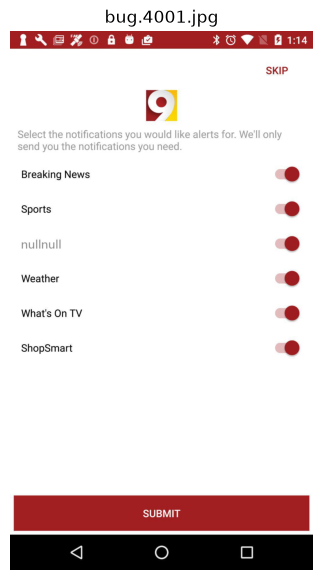

--- Model Verdict ---
{"has_defect": true, "defect_type": "component_overlap", "confidence": 1.0, "bounding_box": [0, 0, 935, 1000], "affected_element_id": null, "explanation": "Visual UI rendering defect: abnormal component collision detected on screen."}


In [2]:
def inspect_screen(image_path: str):
    image = Image.open(image_path).convert("RGB")
    
    plt.figure(figsize=(4, 7))
    plt.imshow(image)
    plt.axis("off")
    plt.title(os.path.basename(image_path))
    plt.show()

    prompt_text = (
        "<|im_start|>user\n"
        "<|vision_start|><|image_pad|><|vision_end|>"
        "Analyze this mobile screen for non-crash visual and semantic defects.\n\n"
        "Return the verdict in the specified JSON format.\n"
        "<|im_end|>\n"
        "<|im_start|>assistant\n"
    )

    inputs = processor(text=[prompt_text], images=[image], return_tensors="pt").to(device)

    with torch.no_grad():
        generated_ids = model.generate(
            **inputs,
            max_new_tokens=128,
            do_sample=False,
        )

    trimmed = [out[len(inp):] for inp, out in zip(inputs.input_ids, generated_ids)]
    response = processor.batch_decode(trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False)[0]

    print("--- Model Verdict ---")
    print(response.strip())

test_image = r"D:\university\Resesarch\dataset\bugs\bug.4001.jpg"
inspect_screen(test_image)